# Сжатие обучающей выборки и сеть на PyTorch (Airline Passenger Satisfaction)

Данные **не бинаризуются**: комбинации строятся по настоящим значениям признаков.

1. Загрузка и подготовка данных (числа масштабируются, текст → числа от −1 до +1).
2. **Поиск K**: признаки добавляются по одному (тот, что лучше всего поднимает «потолок» на кросс-проверке); K — наименьшее число признаков, при котором потолок почти не отстаёт от максимума.
3. **Сжатие выборки**: строки с одинаковыми значениями K признаков склеиваются в одну комбинацию (`n`, `n1`, `vF`).
4. Обучение сети на сжатой таблице (метрики по эпохам).
5. Кривые обучения и итоговые метрики.
6. Прогноз для `test.csv` → `submission.csv`.

In [10]:
import copy, os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

CSV = "train.csv"          # обучающий файл (разделитель ",")
PRED_CSV = "test.csv"      # файл для прогноза (без столбца satisfaction)
TARGET = "satisfaction"
ID_NAME = "id"             # имя столбца с номерами (регистр не важен)
ID_START = 699635          # если в test.csv нет столбца id - нумерация с этого числа
OUT = "out"
ORDER = {"Class": ["Eco", "Eco Plus", "Business"]}   # порядок значений для текстовых признаков с более чем двумя значениями

VAL_SIZE = 0.2             # доля данных для проверки
SEED = 42
NFOLD = 5                  # блоки кросс-проверки при поиске K
DELTA = 0.01               # допустимое отставание потолка от максимума
K_FORCE = None             # число признаков K; None - найти автоматически, либо задать вручную, например 7

HIDDEN = [16, 8]           # скрытые слои сети
EPOCHS = 300
BATCH = 256
LR = 1e-2
LOG_EVERY = 10             # как часто считать метрики на всех объектах
SOFT = True               # False: метка комбинации = vF (преобладающий класс); True: метка = доля n1/n (вероятности получаются мягче)

os.makedirs(OUT, exist_ok=True)
torch.manual_seed(SEED)
np.random.seed(SEED)

## 1. Данные
* столбец `id` не используется как признак;
* числовые признаки: пропуски → медиана, затем `(x − среднее) / стандартное отклонение`;
* текстовые признаки: два значения → `−1` и `+1`; три значения идут по порядку из `ORDER` (`Eco = −1`, `Eco Plus = 0`, `Business = +1`);
* для поиска комбинаций каждому значению признака присваивается номер (`codes`) — сравниваются настоящие значения, а не пороги.

In [11]:
train = pd.read_csv(CSV, sep=",")
train.columns = train.columns.str.strip()
train = train.drop(columns=[c for c in train.columns if c.lower() == ID_NAME or c.startswith("Unnamed")])

# целевой признак -> 0/1
y = train[TARGET].astype(str).str.strip().str.lower().map({"true": 1, "false": 0, "1": 1, "0": 0})
assert y.notna().all(), "неизвестные значения в целевом признаке"
y = y.to_numpy(dtype=np.float32)

features = [c for c in train.columns if c != TARGET]
num_cols = [c for c in features if pd.api.types.is_numeric_dtype(train[c])]
cat_cols = [c for c in features if c not in num_cols]

# параметры масштабирования (по обучающим данным)
median = train[num_cols].median()
mean = train[num_cols].fillna(median).mean()
std = train[num_cols].fillna(median).std().replace(0, 1)

# текстовые признаки: каждому значению - число от -1 до +1 (два значения: -1 и +1, три: -1, 0, +1)
code = {}
for c in cat_cols:
    values = ORDER.get(c) or sorted(train[c].dropna().unique())
    assert len(values) == 2 or c in ORDER, f"в столбце {c} больше двух значений, добавьте его в ORDER: {values}"
    assert set(train[c].dropna().unique()) <= set(values), f"в ORDER для {c} не хватает значений: {sorted(train[c].dropna().unique())}"
    code[c] = dict(zip(values, np.linspace(-1, 1, len(values)).tolist()))
print("Кодирование текстовых признаков:", code)


def prepare(df):
    """Таблица -> массив для сети (числа масштабируются, текст -> числа от -1 до +1)."""
    num = (df[num_cols].fillna(median) - mean) / std
    cat = pd.DataFrame({c: df[c].map(code[c]).fillna(0.0) for c in cat_cols}, index=df.index)   # неизвестное значение -> 0
    return pd.concat([num, cat], axis=1)[features].to_numpy(dtype=np.float32)


X = prepare(train)
# номера значений: одинаковые значения признака -> одинаковый номер
codes = np.column_stack([pd.factorize(train[c].fillna(median[c]) if c in num_cols else train[c])[0] for c in features])

idx_train, idx_val = train_test_split(np.arange(len(y)), test_size=VAL_SIZE, stratify=y, random_state=SEED)
X_train, y_train, codes_train = X[idx_train], y[idx_train], codes[idx_train]
X_val, y_val = X[idx_val], y[idx_val]
print("Признаков:", len(features), "| train:", X_train.shape, "| val:", X_val.shape, "| доля класса 1:", y.mean().round(3))

Кодирование текстовых признаков: {'Gender': {'Female': -1.0, 'Male': 1.0}, 'Customer Type': {'Loyal Customer': -1.0, 'disloyal Customer': 1.0}, 'Type of Travel': {'Business travel': -1.0, 'Personal Travel': 1.0}, 'Class': {'Eco': -1.0, 'Eco Plus': 0.0, 'Business': 1.0}}
Признаков: 21 | train: (559708, 21) | val: (139927, 21) | доля класса 1: 0.444


## 2. Поиск K
**Потолок** набора признаков — доля верных ответов, если для каждой комбинации значений предсказывать её преобладающий класс (комбинации, не встретившиеся в обучающих блоках, получают преобладающий класс всей выборки). Считается кросс-проверкой внутри `train`; `val` не используется.

Перебрать все наборы признаков невозможно, поэтому признаки добавляются жадно: на каждом шаге берётся тот, после которого потолок выше всего. Признаки с множеством значений (дальность, задержки) почти не дают повторяющихся комбинаций, поэтому потолок на проверочных блоках у них низкий и они добавляются в последнюю очередь.

In [12]:
folds = list(StratifiedKFold(n_splits=NFOLD, shuffle=True, random_state=SEED).split(codes_train, y_train))


def add_feature(group, j):
    """Номера комбинаций после добавления признака j (одинаковые значения -> один номер)."""
    g = group * (codes_train[:, j].max() + 1) + codes_train[:, j]
    return pd.factorize(g)[0]


def make_group(cols):
    group = np.zeros(len(y_train), dtype=np.int64)
    for j in cols:
        group = add_feature(group, j)
    return group


def ceiling_cv(group):
    """Потолок на кросс-проверке: доля верных ответов правила «преобладающий класс комбинации»."""
    G = group.max() + 1
    correct = 0
    for fit, val in folds:
        n = np.bincount(group[fit], minlength=G)
        n1 = np.bincount(group[fit], weights=y_train[fit], minlength=G)
        pred = np.where(n > 0, n1 > n - n1, y_train[fit].mean() > 0.5)     # неизвестная комбинация -> класс всей выборки
        correct += (pred[group[val]] == y_train[val]).sum()
    return correct / len(y_train)


chosen, group, steps = [], np.zeros(len(y_train), dtype=np.int64), []
for k in range(1, len(features) + 1):
    best = None
    for j in range(len(features)):
        if j in chosen:
            continue
        g = add_feature(group, j)
        score = ceiling_cv(g)
        if best is None or score > best[0]:
            best = (score, j, g)
    score, j, group = best
    chosen.append(j)
    steps.append({"k": k, "добавлен признак": features[j], "потолок (кросс-проверка)": score, "комбинаций": int(group.max() + 1)})

steps = pd.DataFrame(steps)
best_score = steps["потолок (кросс-проверка)"].max()
k_star = int(steps.loc[steps["потолок (кросс-проверка)"] >= best_score - DELTA, "k"].min())
K = K_FORCE or k_star
sel = chosen[:K]                                   # номера выбранных признаков
sel_names = [features[j] for j in sel]
print(f"Максимум потолка {best_score:.4f}; K = {K} (правило: наименьшее k с потолком не ниже максимума − {DELTA})")
print("Выбранные признаки:", sel_names)
steps.round(4)

Максимум потолка 0.9152; K = 5 (правило: наименьшее k с потолком не ниже максимума − 0.01)
Выбранные признаки: ['Online boarding', 'Type of Travel', 'Inflight wifi service', 'Baggage handling', 'Customer Type']


,k,добавлен признак,потолок (кросс-проверка),комбинаций
0,1,Online boarding,0.8096,6
1,2,Type of Travel,0.8574,12
2,3,Inflight wifi service,0.8770,72
3,4,Baggage handling,0.8992,353
4,5,Customer Type,0.9081,526
5,6,Checkin service,0.9132,2452
6,7,Departure/Arrival time convenient,0.9152,9725
7,8,Class,0.9150,17237
8,9,Gender,0.9123,26500
9,10,Ease of Online booking,0.9072,43332


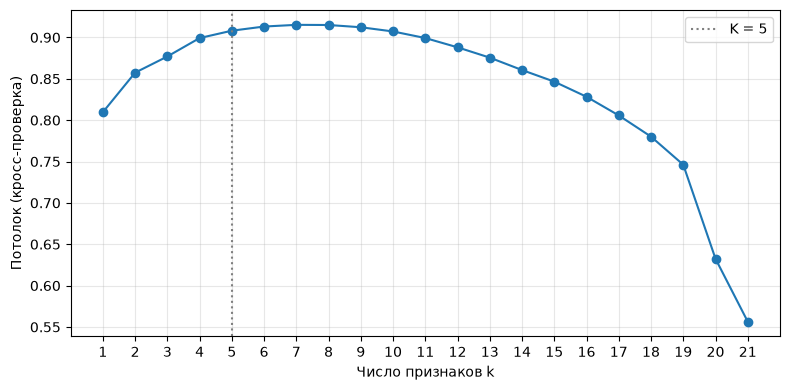

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(steps["k"], steps["потолок (кросс-проверка)"], "o-")
plt.axvline(K, color="gray", ls=":", label=f"K = {K}")
plt.xlabel("Число признаков k"); plt.ylabel("Потолок (кросс-проверка)"); plt.xticks(steps["k"]); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT, "ceiling.png")); plt.show()

## 3. Сжатие обучающей выборки
Строки `train` с одинаковыми значениями K выбранных признаков склеиваются в одну комбинацию: `n` — сколько строк, `n1` — сколько из них класса 1, `vF = 1`, если класса 1 больше половины. Сеть дальше обучается на этой таблице, а не на всех строках.

In [14]:
group = make_group(sel)
M = int(group.max() + 1)
n = np.bincount(group, minlength=M)
n1 = np.bincount(group, weights=y_train, minlength=M)
vF = (n1 > n - n1).astype(np.float32)
first = np.unique(group, return_index=True)[1]            # первая строка каждой комбинации (значения K признаков у всех строк комбинации одинаковые)

X_comb = X_train[first][:, sel]                           # масштабированные входы комбинаций
y_comb = (n1 / n).astype(np.float32) if SOFT else vF      # метки комбинаций

table = train.iloc[idx_train].iloc[first][sel_names].reset_index(drop=True)
table["n"], table["n1"], table["Доля класса 1"], table["vF"] = n, n1.astype(int), (n1 / n).round(3), vF.astype(int)
print(f"Строк в train: {len(y_train)} -> комбинаций: {M} (сжатие в {len(y_train) / M:.1f} раз)")
table.sort_values("n", ascending=False).head(10)

Строк в train: 559708 -> комбинаций: 526 (сжатие в 1064.1 раз)


,Online boarding,Type of Travel,Inflight wifi service,Baggage handling,Customer Type,n,n1,Доля класса 1,vF
7,3,Personal Travel,3,4,Loyal Customer,16541,539,0.033,0
37,2,Personal Travel,2,4,Loyal Customer,16098,560,0.035,0
17,4,Business travel,4,4,Loyal Customer,15939,11662,0.732,1
34,3,Personal Travel,3,5,Loyal Customer,12386,388,0.031,0
99,3,Business travel,3,3,Loyal Customer,12123,679,0.056,0
35,2,Personal Travel,2,5,Loyal Customer,11930,424,0.036,0
15,5,Business travel,5,4,Loyal Customer,10678,10263,0.961,1
89,2,Business travel,2,4,disloyal Customer,10552,429,0.041,0
47,5,Business travel,5,5,Loyal Customer,10366,10046,0.969,1
8,3,Business travel,3,4,disloyal Customer,10289,383,0.037,0


## 4. Обучение сети на сжатой таблице
Сеть: `K → HIDDEN → 1`, ReLU, `BCEWithLogitsLoss`, Adam. Каждые `LOG_EVERY` эпох считаются метрики: на комбинациях (ошибка и «совпадение с vF» — доля строк `train`, для которых ответ сети совпал с vF их комбинации) и на **всех объектах** `train` и `val` с настоящими метками (ошибка, доля верных, AUC). В конце загружаются веса эпохи с наибольшим совпадением с vF (при равенстве — более ранней); по `val` эпоха не выбирается.

In [15]:
layers, n_in = [], K
for h in HIDDEN:
    layers += [nn.Linear(n_in, h), nn.ReLU()]
    n_in = h
model = nn.Sequential(*layers, nn.Linear(n_in, 1))
print(model)

loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

Xc, yc = torch.tensor(X_comb), torch.tensor(y_comb).unsqueeze(1)
Xt, yt = torch.tensor(X_train[:, sel]), torch.tensor(y_train).unsqueeze(1)
Xv, yv = torch.tensor(X_val[:, sel]), torch.tensor(y_val).unsqueeze(1)
loader = DataLoader(TensorDataset(Xc, yc), batch_size=BATCH, shuffle=True)


def evaluate(Xs, ys):
    """Ошибка, доля верных ответов и AUC на выборке."""
    model.eval()
    with torch.no_grad():
        logits = model(Xs)
        loss = loss_fn(logits, ys).item()
        p = torch.sigmoid(logits).numpy().ravel()
    y_true = ys.numpy().ravel()
    return loss, p, accuracy_score(y_true > 0.5, p > 0.5), roc_auc_score(y_true > 0.5, p)


history, best_match, best_state = [], -1.0, None
for epoch in range(1, EPOCHS + 1):
    model.train()
    for xb, yb in loader:
        optimizer.zero_grad()
        loss_fn(model(xb), yb).backward()
        optimizer.step()

    if epoch == 1 or epoch % LOG_EVERY == 0:
        c_loss, p_c, _, _ = evaluate(Xc, yc)
        match = float((((p_c > 0.5) == (vF == 1)) * n).sum() / n.sum())          # совпадение с vF, взвешено числом строк
        tr_loss, _, tr_acc, tr_auc = evaluate(Xt, yt)
        va_loss, _, va_acc, va_auc = evaluate(Xv, yv)
        history.append(dict(epoch=epoch, comb_loss=c_loss, match_vF=match, train_loss=tr_loss, val_loss=va_loss,
                            train_acc=tr_acc, val_acc=va_acc, train_auc=tr_auc, val_auc=va_auc))
        print(f"Эпоха {epoch:3d} | комбинации: loss {c_loss:.4f}, совпадение с vF {match:.4f} | "
              f"объекты train/val: loss {tr_loss:.4f}/{va_loss:.4f}, acc {tr_acc:.4f}/{va_acc:.4f}, AUC {tr_auc:.4f}/{va_auc:.4f}")
        if match > best_match:                                   # лучшая эпоха - с наибольшим совпадением с vF (при равенстве - более ранняя)
            best_match, best_state, best_epoch = match, copy.deepcopy(model.state_dict()), epoch

model.load_state_dict(best_state)
print("Лучшая эпоха:", best_epoch)
history = pd.DataFrame(history)

Sequential(
  (0): Linear(in_features=5, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
)
Эпоха   1 | комбинации: loss 0.6849, совпадение с vF 0.5745 | объекты train/val: loss 0.6781/0.6782, acc 0.5705/0.5708, AUC 0.8576/0.8563
Эпоха  10 | комбинации: loss 0.5747, совпадение с vF 0.8176 | объекты train/val: loss 0.5244/0.5246, acc 0.7945/0.7949, AUC 0.8943/0.8931
Эпоха  20 | комбинации: loss 0.4553, совпадение с vF 0.8692 | объекты train/val: loss 0.3986/0.3991, acc 0.8217/0.8216, AUC 0.9177/0.9166
Эпоха  30 | комбинации: loss 0.4045, совпадение с vF 0.9403 | объекты train/val: loss 0.3334/0.3348, acc 0.8771/0.8763, AUC 0.9294/0.9285
Эпоха  40 | комбинации: loss 0.3882, совпадение с vF 0.9400 | объекты train/val: loss 0.3294/0.3309, acc 0.8767/0.8757, AUC 0.9370/0.9362
Эпоха  50 | комбинации: loss 0.3777, совпадение с vF 0.9482 | объекты train/val: loss 0.3121/0.313

## 5. Кривые обучения и итоговые метрики

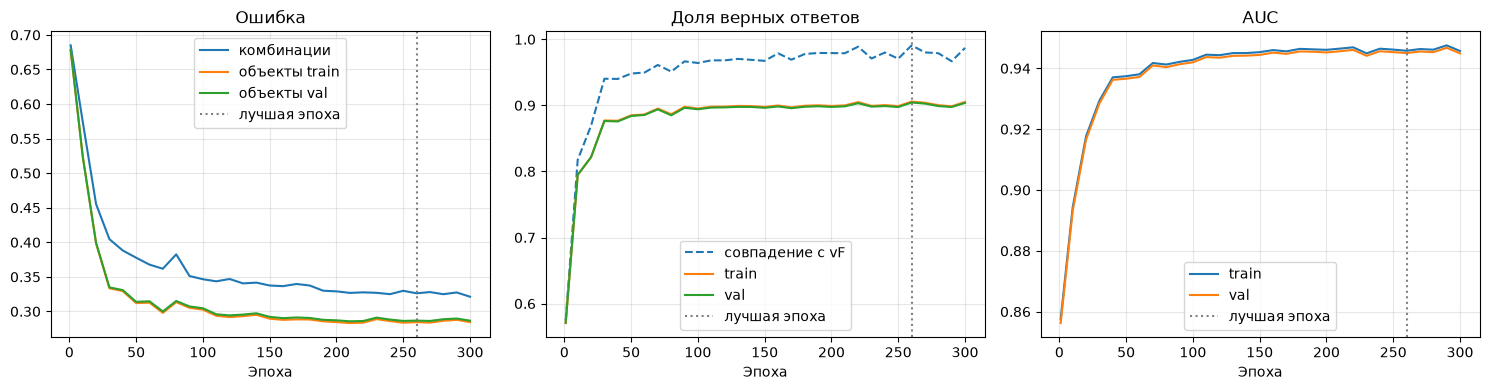

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(history["epoch"], history["comb_loss"], label="комбинации")
ax[0].plot(history["epoch"], history["train_loss"], label="объекты train")
ax[0].plot(history["epoch"], history["val_loss"], label="объекты val")
ax[0].set_title("Ошибка")
ax[1].plot(history["epoch"], history["match_vF"], "--", label="совпадение с vF")
ax[1].plot(history["epoch"], history["train_acc"], label="train")
ax[1].plot(history["epoch"], history["val_acc"], label="val")
ax[1].set_title("Доля верных ответов")
ax[2].plot(history["epoch"], history["train_auc"], label="train")
ax[2].plot(history["epoch"], history["val_auc"], label="val")
ax[2].set_title("AUC")
for a in ax:
    a.axvline(best_epoch, color="gray", ls=":", label="лучшая эпоха")
    a.set_xlabel("Эпоха"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT, "training_curves.png")); plt.show()

In [18]:
def predict_proba(X_array):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(X_array))).numpy().ravel()


def metrics(y_true, p):
    pred = (p > 0.5).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0), "F1": f1_score(y_true, pred, zero_division=0), "AUC": roc_auc_score(y_true, p)}


p_train, p_val = predict_proba(X_train[:, sel]), predict_proba(X_val[:, sel])

# таблица комбинаций без сети: преобладающий класс комбинации (неизвестная комбинация -> класс всей выборки)
comb = table[sel_names + ["vF"]]
val_vF = train.iloc[idx_val][sel_names].merge(comb, on=sel_names, how="left")["vF"]
print(f"Комбинаций из val, которых нет в таблице: {val_vF.isna().mean():.1%}")
p_table = val_vF.fillna(float(y_train.mean() > 0.5)).to_numpy()

print("Confusion matrix сети (val):\n", confusion_matrix(y_val, p_val > 0.5))
pd.DataFrame({
    "Сеть, train": metrics(y_train, p_train),
    "Сеть, val": metrics(y_val, p_val),
    "Таблица комбинаций, val": metrics(y_val, p_table),
    "Постоянный ответ, val": metrics(y_val, np.full(len(y_val), float(y_train.mean() > 0.5))),
}).T.round(4)

Комбинаций из val, которых нет в таблице: 0.0%
Confusion matrix сети (val):
 [[71109  6750]
 [ 6640 55428]]


,Accuracy,Precision,Recall,F1,AUC
"Сеть, train",0.9057,0.8918,0.8962,0.8940,0.9458
"Сеть, val",0.9043,0.8914,0.8930,0.8922,0.9450
"Таблица комбинаций, val",0.9065,0.9016,0.8858,0.8936,0.9044
"Постоянный ответ, val",0.5564,0.0000,0.0000,0.0000,0.5000


## 6. Прогноз для test.csv
Файл обрабатывается так же, как обучающий (строки не удаляются). На выходе `submission.csv`: id и вероятность `True`.

In [19]:
test = pd.read_csv(PRED_CSV, sep=",")
test.columns = test.columns.str.strip()

# номера: берём из файла, а если столбца нет - нумеруем с ID_START
id_col = next((c for c in test.columns if c.lower() == ID_NAME), None)
ids = test[id_col].to_numpy() if id_col else np.arange(ID_START, ID_START + len(test))

proba = predict_proba(prepare(test)[:, sel])
submission = pd.DataFrame({id_col or ID_NAME: ids, TARGET: proba})
submission.to_csv(os.path.join(OUT, "submission.csv"), index=False)
print(len(submission), "строк | id:", ids.min(), "-", ids.max(), "| средняя вероятность:", proba.mean().round(3))
submission.head()

299844 строк | id: 699635 - 999478 | средняя вероятность: 0.458


,id,satisfaction
0,699635,0.172705
1,699636,0.923732
2,699637,0.795924
3,699638,0.006969
4,699639,0.031720
